# Nonlinear regression: logistic growth for the four diets

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import least_squares
from scipy.stats import t

Third notebook about the `ChickWeight` data. Now we fit the four diets in one model: each diet has its own logistic growth curve and its own variance function, and all share the same $\sigma^2$. With the estimators and their standard errors we can compare the diets.

In [2]:
dat = pd.read_csv('chick_weight.csv')
dat = dat.rename(columns={'Weight': 'weight'})
dat = dat.drop('Chick', axis=1)
dat['Diet'] = dat['Diet'].astype('category')

alpha = 0.05

In [3]:
# Colors: one for each diet
diet_colors = {1: '#0072B2', 2: '#E69F00', 3: '#009E73', 4: '#CC79A7'}
diets = [1, 2, 3, 4]

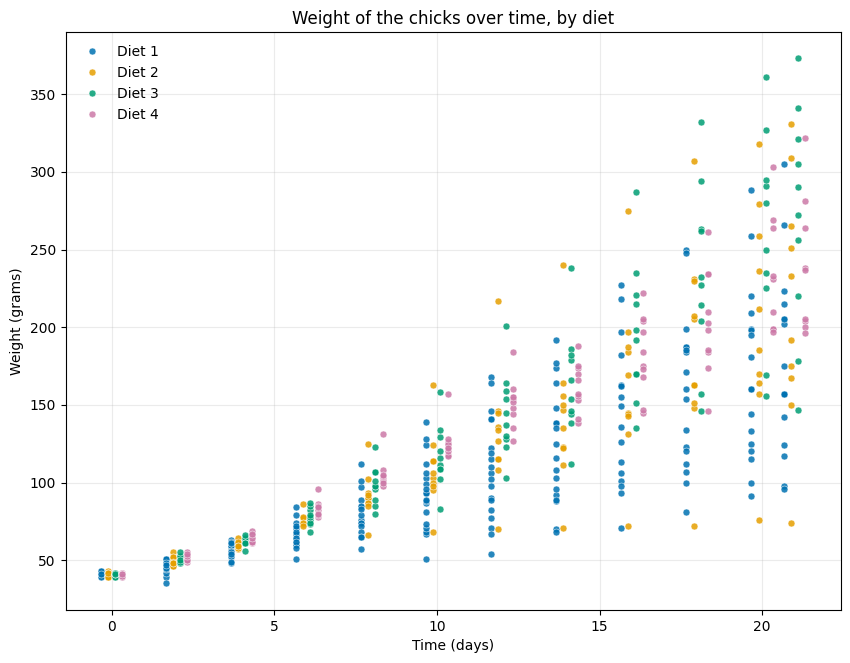

In [4]:
fig, ax = plt.subplots(figsize=(10, 7.5))
rng = np.random.default_rng(0)
for diet in diets:
    dat_diet = dat[dat['Diet'] == diet]
    # A small horizontal shift for each diet, to see the points
    ax.plot(dat_diet['Time'] + 0.22*(diet-2.5), dat_diet['weight'], 'o', color=diet_colors[diet], markersize=5,
            markeredgecolor='white', markeredgewidth=0.4, alpha=0.85, label=f'Diet {diet}')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Weight (grams)')
ax.set_title('Weight of the chicks over time, by diet')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

In [5]:
Y = dat['weight'].to_numpy(dtype=float)
x = dat['Time'].to_numpy(dtype=float)
d = dat['Diet'].cat.codes.to_numpy()   # 0, 1, 2, 3 for the diets 1, 2, 3, 4
n = len(Y)
p = 12

print('Observations:', n)

Observations: 578


## Let's stabilize the variance

As in the second notebook, for each diet the logarithm of the variance is modelled as a quadratic function of the time,
$$\mathrm{Var}(y \mid t, \text{diet } k) = \sigma^2\exp(\delta_{1k}t + \delta_{2k}t^2).$$

In [6]:
dat_var = dat[['weight','Diet','Time']].groupby(['Diet','Time'], observed=True).var().reset_index()
dat_var = dat_var.rename(columns={'weight':'var'})
dat_var['log_var'] = np.log(dat_var['var'])

dat_var.head()

,Diet,Time,var,log_var
0,1,0,0.989474,-0.010582
1,1,2,18.302632,2.907045
2,1,4,17.040936,2.835618
3,1,6,60.175439,4.097264
4,1,8,189.783626,5.245885


In [7]:
dat_var = pd.merge(dat, dat_var, how='left', on=['Diet','Time'])

# One column of Time and one of Time^2 for each diet
X_aux = np.zeros((n, 8))
for k in range(4):
    X_aux[d == k, k] = x[d == k]
    X_aux[d == k, 4+k] = x[d == k]**2
y_aux = dat_var['log_var'].to_numpy()

log_var_fit = sm.OLS(y_aux, X_aux).fit()
delta = np.array(log_var_fit.params)

pd.DataFrame({'delta_1 (Time)': delta[:4], 'delta_2 (Time^2)': delta[4:]}, index=[f'Diet {k}' for k in diets]).round(4)

,delta_1 (Time),delta_2 (Time^2)
Diet 1,0.8386,-0.0220
Diet 2,0.7544,-0.0161
Diet 3,0.7211,-0.0150
Diet 4,0.5918,-0.0114


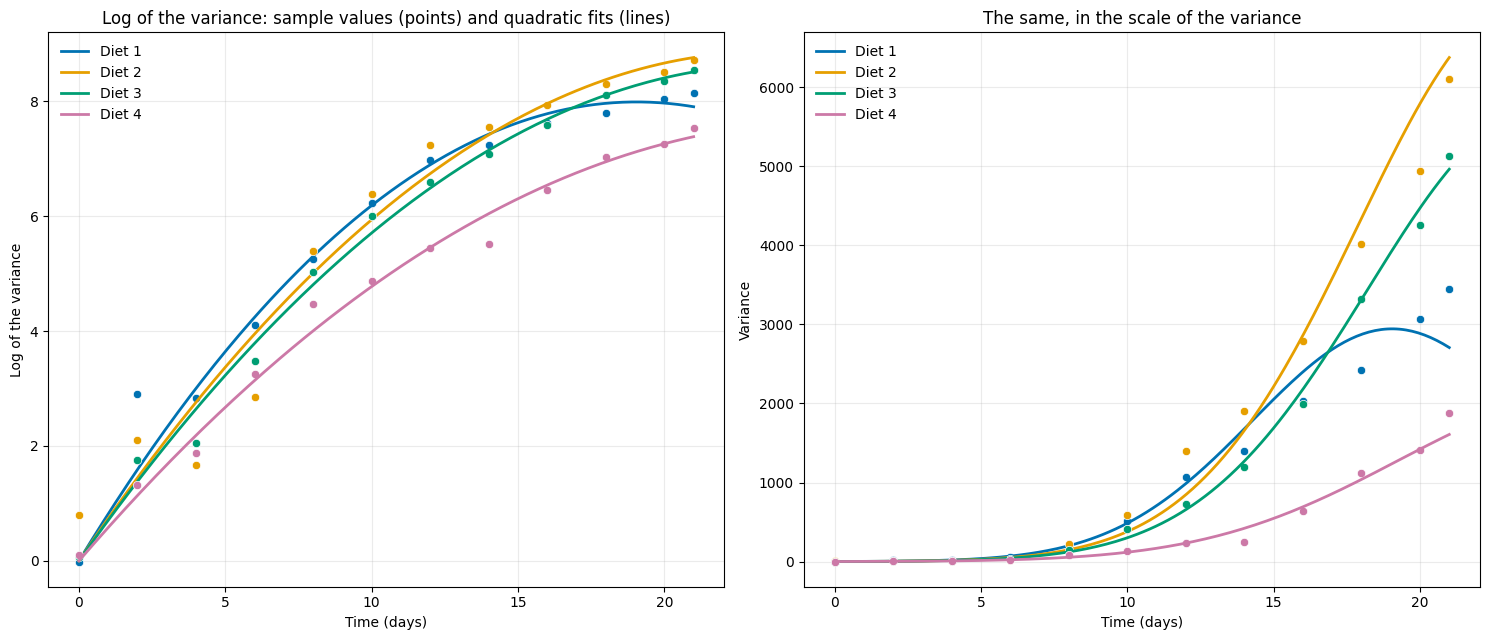

In [8]:
x_grid = np.linspace(0, 21, 200)
var_table = dat_var.groupby(['Diet', 'Time'], observed=True)['var'].first().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for k, diet in enumerate(diets):
    rows = var_table[var_table['Diet'] == diet]
    fitted = delta[k]*x_grid + delta[4+k]*x_grid**2
    axes[0].plot(rows['Time'], np.log(rows['var']), 'o', color=diet_colors[diet], markersize=6, markeredgecolor='white',
                 markeredgewidth=0.5)
    axes[0].plot(x_grid, fitted, color=diet_colors[diet], lw=2, label=f'Diet {diet}')
    axes[1].plot(rows['Time'], rows['var'], 'o', color=diet_colors[diet], markersize=6, markeredgecolor='white',
                 markeredgewidth=0.5)
    axes[1].plot(x_grid, np.exp(fitted), color=diet_colors[diet], lw=2, label=f'Diet {diet}')
axes[0].set_ylabel('Log of the variance')
axes[0].set_title('Log of the variance: sample values (points) and quadratic fits (lines)')
axes[1].set_ylabel('Variance')
axes[1].set_title('The same, in the scale of the variance')
for ax in axes:
    ax.set_xlabel('Time (days)')
    ax.legend(loc='upper left', frameon=False)
    ax.grid(True, alpha=0.25)
plt.tight_layout()

In [9]:
def sigma_1(t, k):
    # Factor that stabilizes the variance, for the time t and the diet with index k
    return np.exp(-0.5*(delta[k]*t + delta[4+k]*t**2))

def logistic_gowth(theta, t, k):
    # theta = (M_1,...,M_4, r_1,...,r_4, b_1,...,b_4)
    return theta[k]/(1+np.exp(-theta[4+k]*(t-theta[8+k])))

dat_sigma_1 = sigma_1(x, d)
dat['weight_transform'] = Y*dat_sigma_1

The variance of the transformed weights is approx. 1 for all diets and times

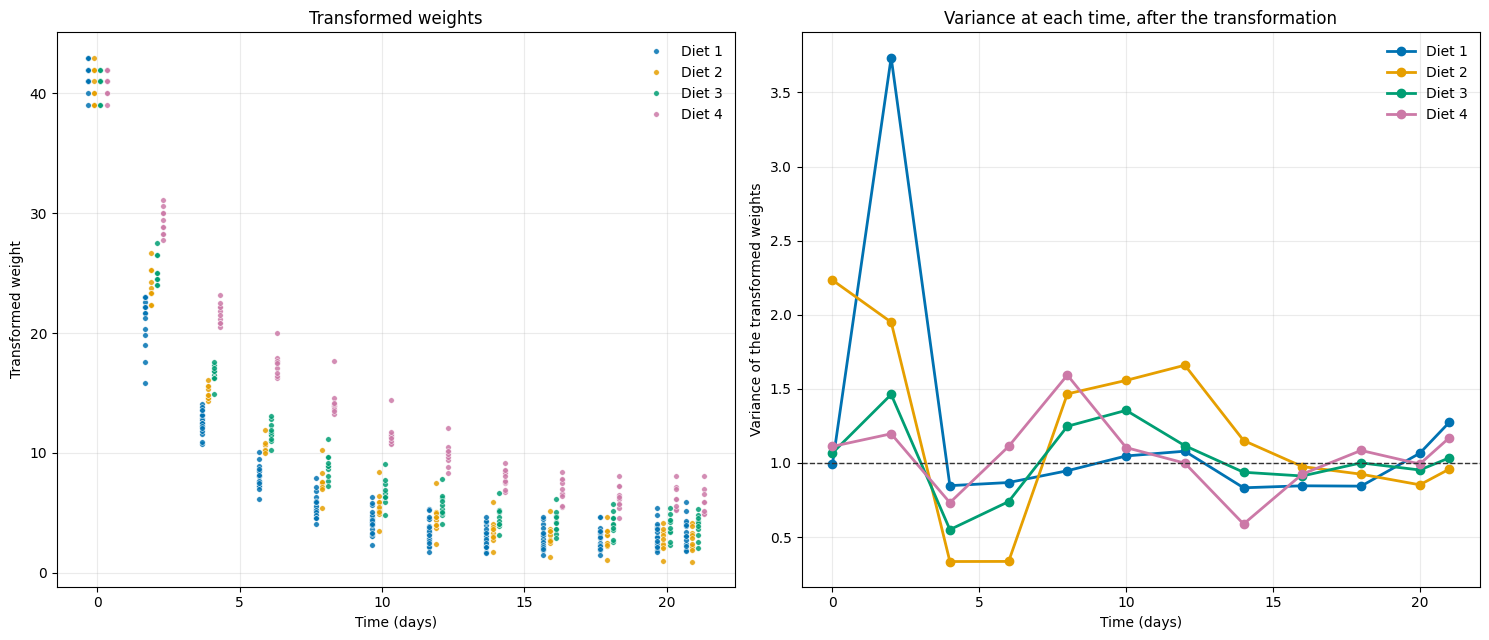

In [10]:
var_transform = dat[['weight_transform','Diet','Time']].groupby(['Diet','Time'], observed=True).var().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for diet in diets:
    dat_diet = dat[dat['Diet'] == diet]
    axes[0].plot(dat_diet['Time'] + 0.22*(diet-2.5), dat_diet['weight_transform'], 'o', color=diet_colors[diet],
                 markersize=4, markeredgecolor='white', markeredgewidth=0.4, alpha=0.85, label=f'Diet {diet}')
    rows = var_transform[var_transform['Diet'] == diet]
    axes[1].plot(rows['Time'], rows['weight_transform'], 'o-', color=diet_colors[diet], lw=2, label=f'Diet {diet}')
axes[0].set_ylabel('Transformed weight')
axes[0].set_title('Transformed weights')
axes[1].axhline(1, ls='--', color='#333333', lw=1)
axes[1].set_ylabel('Variance of the transformed weights')
axes[1].set_title('Variance at each time, after the transformation')
for ax in axes:
    ax.set_xlabel('Time (days)')
    ax.legend(loc='upper right', frameon=False)
    ax.grid(True, alpha=0.25)
plt.tight_layout()

## Weighted nonlinear least squares

In [11]:
def fun(theta):
    return dat_sigma_1*logistic_gowth(theta, x, d) - dat['weight_transform'].to_numpy()

theta0 = [Y.max()]*4 + [0.1]*4 + [15]*4
logistic_growth_transform = least_squares(fun, theta0)
theta_star = logistic_growth_transform.x
F_matrix = logistic_growth_transform.jac

hat_sigma2_transform = sum((logistic_growth_transform.fun)**2)/(n-p)
print('sigma^2:', hat_sigma2_transform)

sigma^2: 1.1189191612585543


In [12]:
var_matrix_params = hat_sigma2_transform * np.linalg.inv(F_matrix.T @ F_matrix)

# Significance of the estimators
se_params = np.sqrt(np.diag(var_matrix_params))
t_score = theta_star/se_params
p_value = 2*(1-t.cdf(np.abs(t_score), n-p))
q_t = t.ppf(1-alpha/2, n-p)

names = [f'{name}, diet {k}' for name in ['M', 'r', 'b'] for k in diets]
results = pd.DataFrame({'estimate': theta_star, 'std. error': se_params, 't': t_score, 'p-value': p_value,
                        'lower': theta_star - q_t*se_params, 'upper': theta_star + q_t*se_params}, index=names)
results.round(4)

,estimate,std. error,t,p-value,lower,upper
"M, diet 1",631.1635,326.7877,1.9314,0.0539,-10.7013,1273.0282
"M, diet 2",379.4454,85.9936,4.4125,0.0000,210.5399,548.3510
"M, diet 3",568.0829,123.3053,4.6071,0.0000,325.8910,810.2748
"M, diet 4",307.3635,20.0576,15.3240,0.0000,267.9670,346.7600
"r, diet 1",0.0857,0.0064,13.4374,0.0000,0.0732,0.0982
"r, diet 2",0.1174,0.0074,15.9649,0.0000,0.1030,0.1319
"r, diet 3",0.1203,0.0055,21.9477,0.0000,0.1096,0.1311
"r, diet 4",0.1475,0.0046,32.3197,0.0000,0.1385,0.1565
"b, diet 1",31.0528,8.6636,3.5843,0.0004,14.0361,48.0695
"b, diet 2",18.0787,3.1994,5.6506,0.0000,11.7945,24.3629


### Comparing the diets

Estimators and 95% confidence intervals of the three parameters. The growth rates $r$ are estimated precisely. The maximum weights $M$ are not: no diet was observed long enough to see the growth stop.

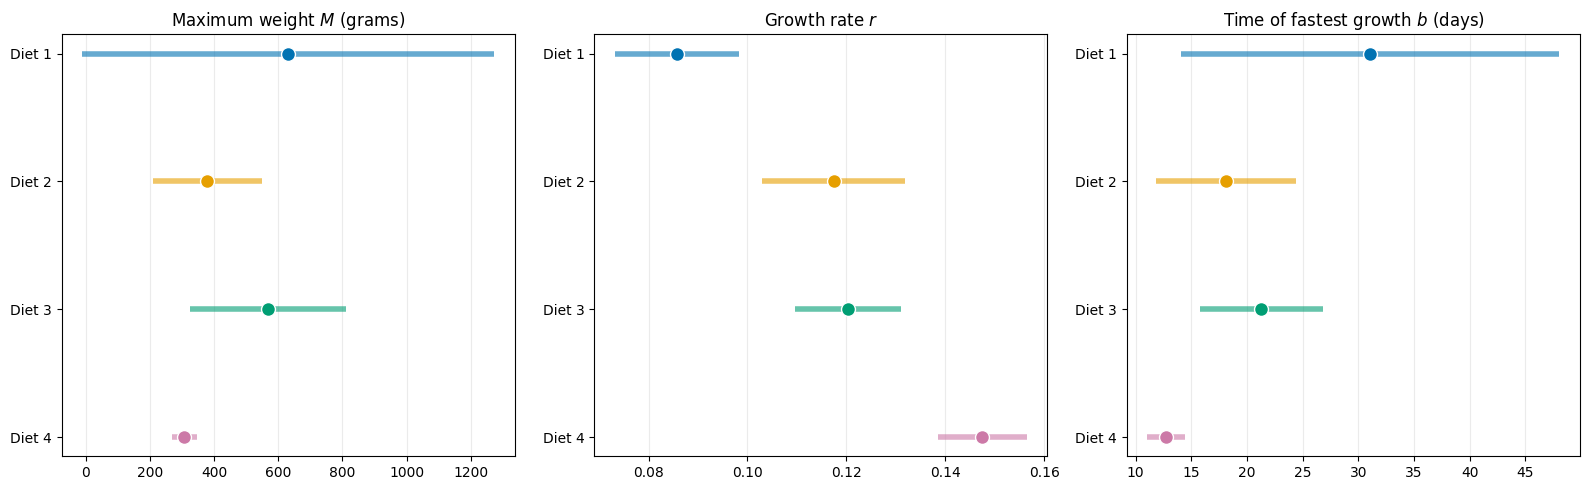

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
parameter_titles = ['Maximum weight $M$ (grams)', 'Growth rate $r$', 'Time of fastest growth $b$ (days)']
for j, ax in enumerate(axes):
    for k, diet in enumerate(diets):
        row = results.iloc[4*j+k]
        ax.hlines(k, row['lower'], row['upper'], color=diet_colors[diet], lw=4, alpha=0.6)
        ax.plot(row['estimate'], k, 'o', color=diet_colors[diet], markersize=10, markeredgecolor='white', markeredgewidth=1)
    ax.set_yticks(range(4), [f'Diet {k}' for k in diets])
    ax.invert_yaxis()
    ax.set_title(parameter_titles[j])
    ax.grid(True, axis='x', alpha=0.25)
plt.tight_layout()

## Confidence and prediction intervals

For the diet $k$, the variance of the fitted curve is $F_t\,V_k\,F_t^T$, where $V_k$ is the block of the covariance matrix of the three parameters of that diet, and the variance of a new observation adds $\hat\sigma^2\exp(\delta_{1k}t + \delta_{2k}t^2)$.

In [14]:
def F_1(t,M,r,b):
    return(1/(1+np.exp(-r*(t-b))))

def F_2(t,M,r,b):
    return((M*(t-b)*np.exp(-r*(t-b)))/(1+np.exp(-r*(t-b)))**2)

def F_3(t,M,r,b):
    return((-M*r*np.exp(-r*(t-b)))/(1+np.exp(-r*(t-b)))**2)

def predict_diet(k, X0):
    # Fitted curve, confidence interval and prediction interval for the diet with index k
    idx = [k, 4+k, 8+k]
    M, r, b = theta_star[idx]
    y0 = M/(1+np.exp(-r*(X0-b)))

    aux_delta = np.vstack([F_1(X0, M, r, b), F_2(X0, M, r, b), F_3(X0, M, r, b)]).T
    sist_var = np.sum((aux_delta @ var_matrix_params[np.ix_(idx, idx)]) * aux_delta, axis=1)
    erro_var = hat_sigma2_transform * np.exp(delta[k]*X0 + delta[4+k]*X0**2)

    ci = q_t*np.sqrt(sist_var)
    pi = q_t*np.sqrt(erro_var + sist_var)
    return y0, y0-ci, y0+ci, y0-pi, y0+pi

def plot_diet(ax, diet, t_max):
    k = diet-1
    color = diet_colors[diet]
    X0 = np.linspace(0, t_max, 300)
    y0, low_conf, upp_conf, low_pred, upp_pred = predict_diet(k, X0)

    ax.fill_between(X0, low_pred, upp_pred, color=color, alpha=0.15, linewidth=0, label='95% prediction interval')
    ax.fill_between(X0, low_conf, upp_conf, color=color, alpha=0.35, linewidth=0, label='95% confidence interval (mean)')
    ax.plot(X0, y0, color=color, lw=2.5, label='Fitted logistic growth')
    ax.plot(x[d == k], Y[d == k], 'o', color=color, markersize=5, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data')
    ax.set_title(f'Diet {diet}')
    ax.grid(True, alpha=0.25)

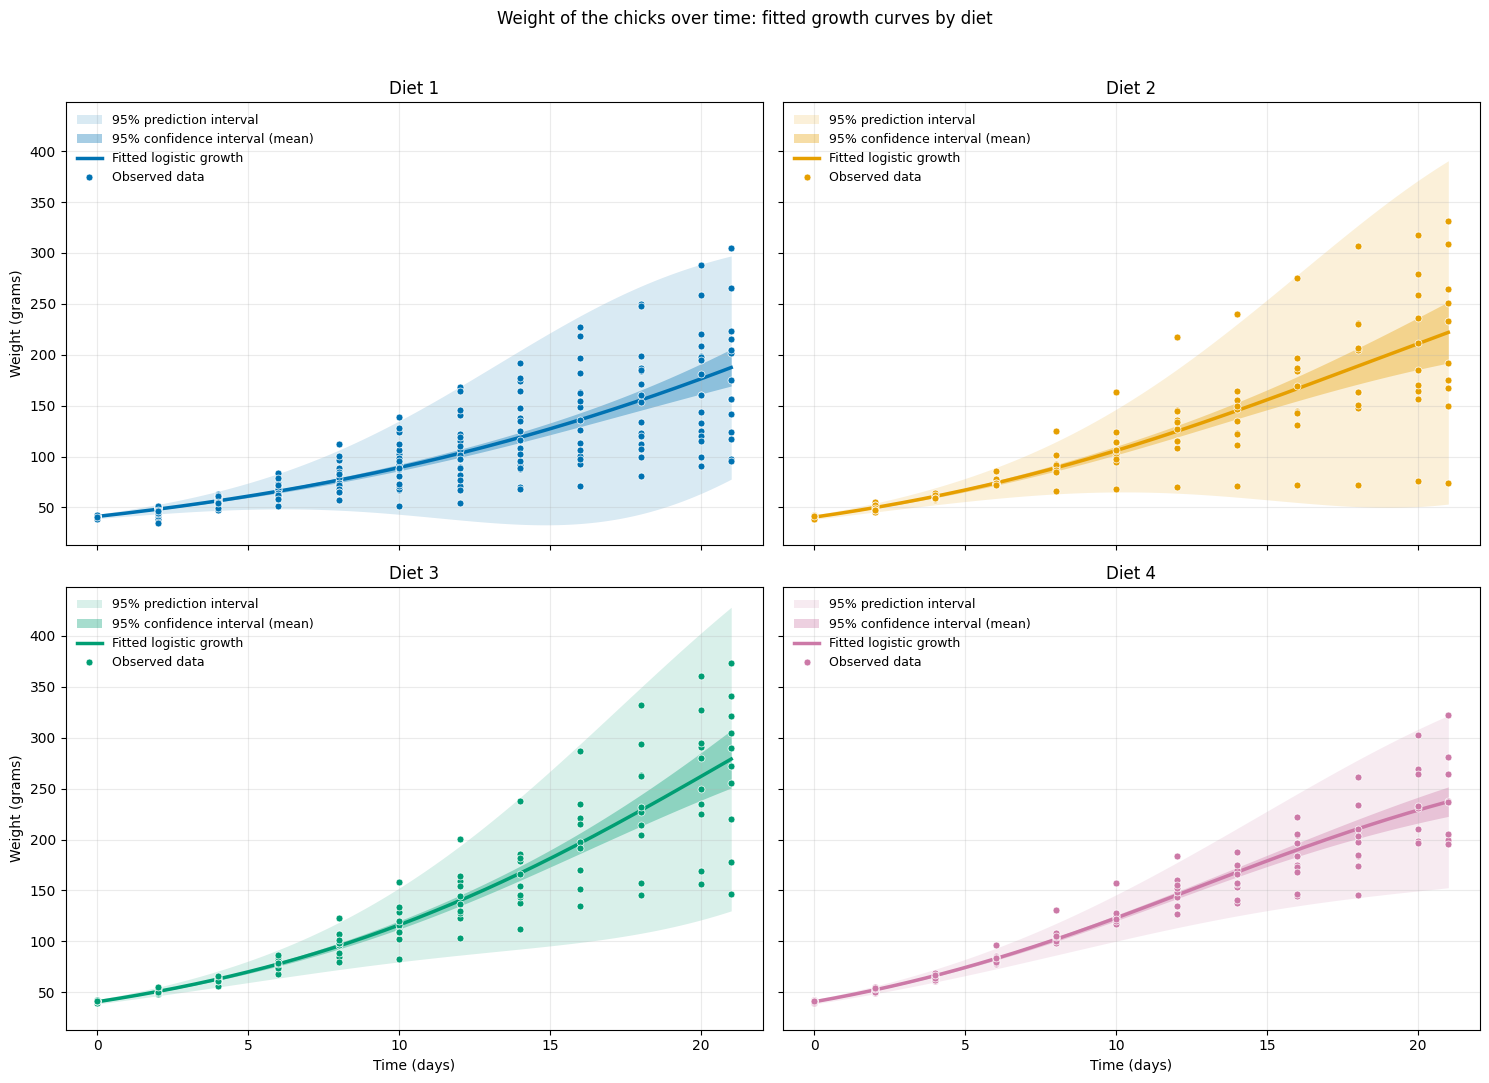

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
for ax, diet in zip(axes.ravel(), diets):
    plot_diet(ax, diet, 21)
    ax.legend(loc='upper left', frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel('Time (days)')
for ax in axes[:, 0]:
    ax.set_ylabel('Weight (grams)')
fig.suptitle('Weight of the chicks over time: fitted growth curves by diet')
fig.tight_layout(rect=(0, 0, 1, 0.96))

### The four curves together

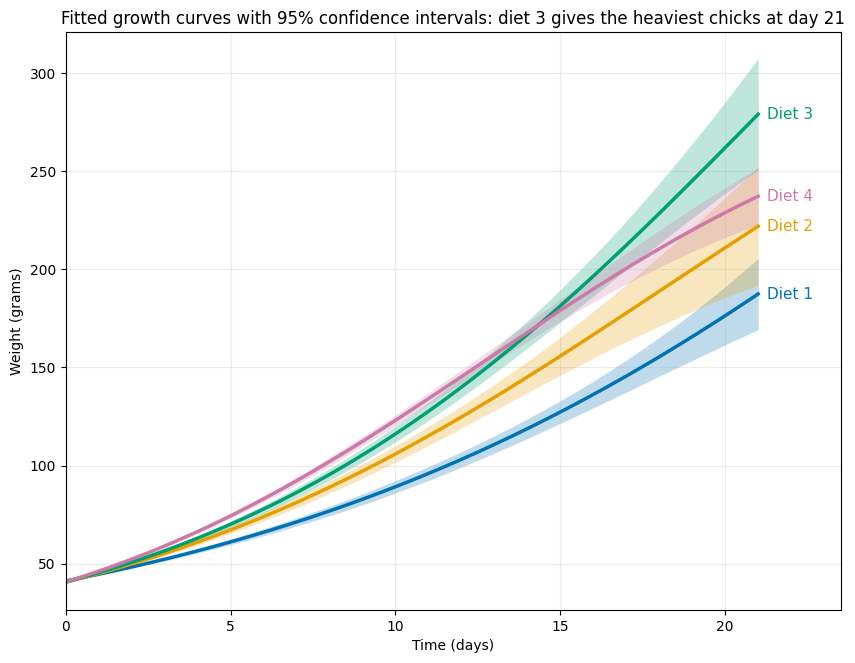

In [16]:
fig, ax = plt.subplots(figsize=(10, 7.5))
X0 = np.linspace(0, 21, 300)
for diet in diets:
    y0, low_conf, upp_conf, low_pred, upp_pred = predict_diet(diet-1, X0)
    ax.fill_between(X0, low_conf, upp_conf, color=diet_colors[diet], alpha=0.25, linewidth=0)
    ax.plot(X0, y0, color=diet_colors[diet], lw=2.5)
    ax.annotate(f'Diet {diet}', (21, y0[-1]), xytext=(6, 0), textcoords='offset points', va='center',
                color=diet_colors[diet], fontsize=11)
ax.set_xlim(0, 23.5)
ax.set_xlabel('Time (days)')
ax.set_ylabel('Weight (grams)')
ax.set_title('Fitted growth curves with 95% confidence intervals: diet 3 gives the heaviest chicks at day 21')
ax.grid(True, alpha=0.25)

## Predicting beyond the observed days

Predictions up to day 50. As we saw in the second notebook, outside the observed range both the growth curve and the variance function are extrapolations: the bands show how little the data say about the maximum weight, and they depend on a variance model that was only checked until day 21.

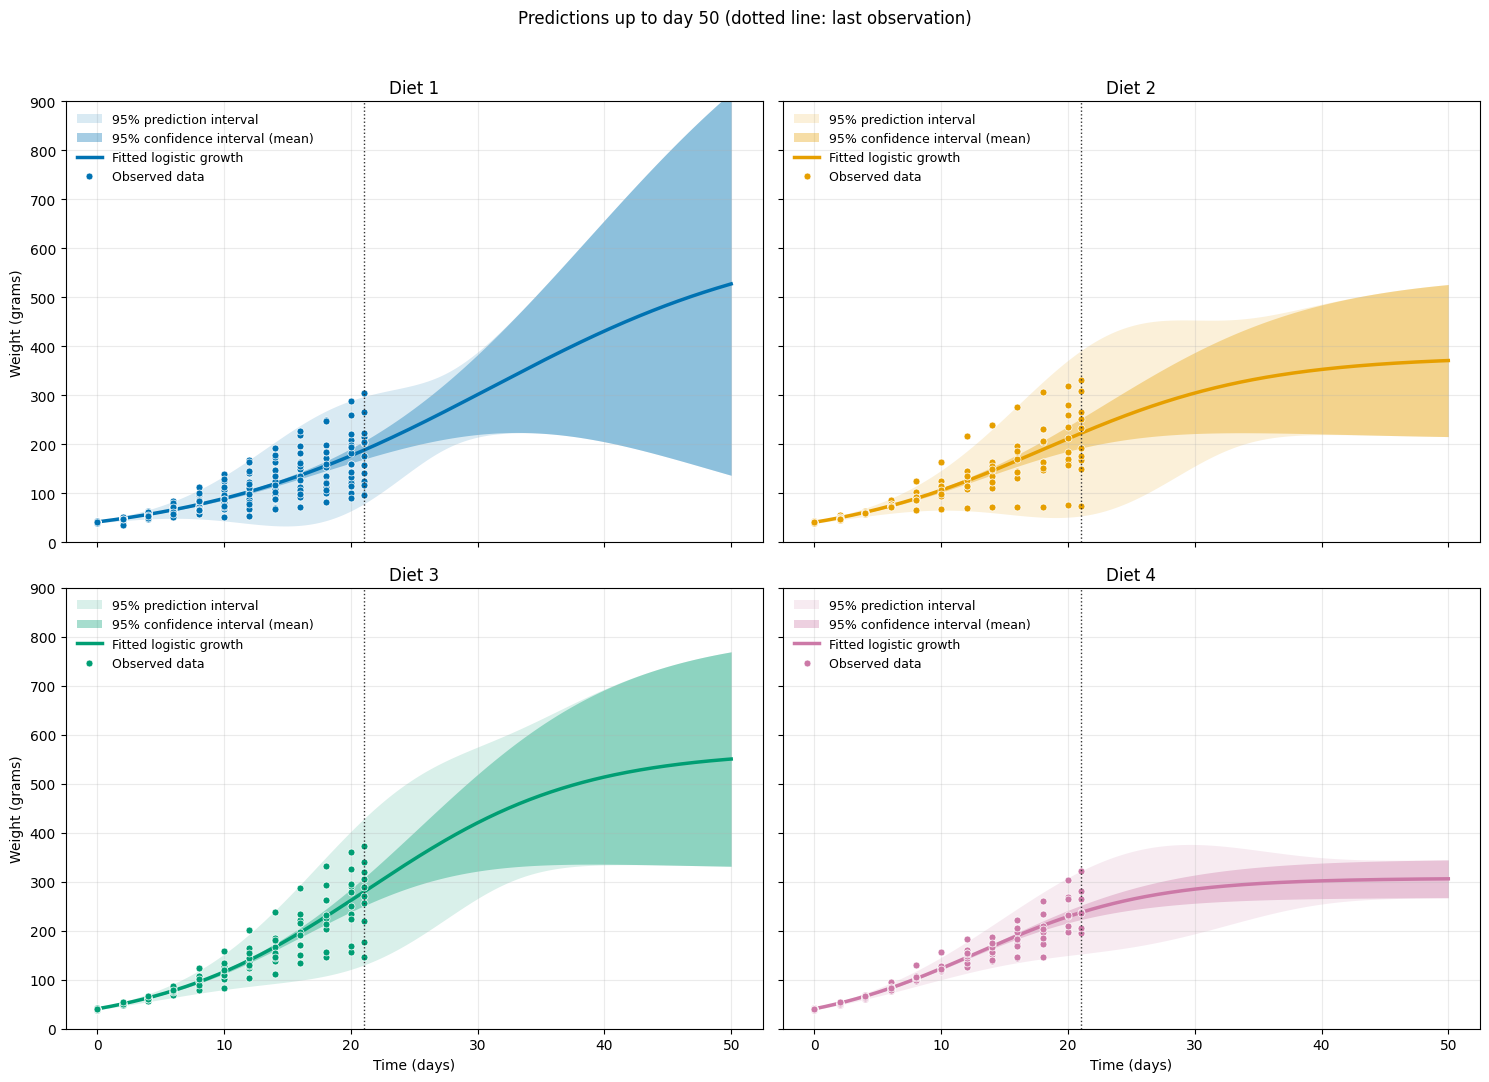

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
for ax, diet in zip(axes.ravel(), diets):
    plot_diet(ax, diet, 50)
    ax.axvline(21, ls=':', color='#333333', lw=1)
    ax.set_ylim(0, 900)
    ax.legend(loc='upper left', frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel('Time (days)')
for ax in axes[:, 0]:
    ax.set_ylabel('Weight (grams)')
fig.suptitle('Predictions up to day 50 (dotted line: last observation)')
fig.tight_layout(rect=(0, 0, 1, 0.96))